# Behavioral diversity: Behavior Prior vs Motion Prior

Compare the behavioral diversity of random-generation rollouts from two trained priors against each other and against their respective encoder-decoder baselines, across **all** noise conditions.

**Naming.** *Motion Prior* = the PULSE prior network (file: `generation_rollout_PULSE_fc_49.h5`). *Behavior Prior* = the RGM (Random Generation Module) network (file: `generation_rollout_rgm_54.h5`).

Pipeline:
1. Load both rollout H5 files and compute egocentric kinematic features per sliding window.
2. Joint PCA(50) across **all** policies in **both** files — a single shared embedding.
3. KMeans(K=40) on the joint embedding — a single shared cluster basis.
4. Paired clip-level bootstrap (B=500) for 95% CIs and one-sided p-values on each policy and each Behavior–Motion comparison.
5. One paper-ready figure of the noise sweep with CIs and encoder-decoder baselines.

In [1]:
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

DATA_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/generation_rollout")
OUTPUT_DIR = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/behavioral_diversity")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Motion Prior":   DATA_DIR / "generation_rollout_PULSE_fc_49.h5",
    "Behavior Prior": DATA_DIR / "generation_rollout_rgm_54.h5",
}

# Per file, list (h5_key_prefix, condition_label).
POLICY_SCHEMA = {
    "Motion Prior": [
        ("student_encoder_decoder", "enc_dec"),
        ("prior_deterministic",     "deterministic"),
        ("prior_logvar_-4",         "logvar=-4"),
        ("prior_logvar_-3",         "logvar=-3"),
        ("prior_logvar_-2",         "logvar=-2"),
        ("prior_logvar_-1",         "logvar=-1"),
        ("prior_logvar_-0.5",       "logvar=-0.5"),
        ("prior_logvar_0",          "logvar=0"),
    ],
    "Behavior Prior": [
        ("student_encoder_decoder", "enc_dec"),
        ("rgm_deterministic",       "deterministic"),
        ("rgm_logvar_-4",           "logvar=-4"),
        ("rgm_logvar_-3",           "logvar=-3"),
        ("rgm_logvar_-2",           "logvar=-2"),
        ("rgm_logvar_-1",           "logvar=-1"),
        ("rgm_logvar_-0.5",         "logvar=-0.5"),
        ("rgm_logvar_0",            "logvar=0"),
    ],
}

# Display order on the noise-sweep x-axis (excludes enc_dec, which is shown as baseline).
CONDITION_ORDER = [
    "deterministic", "logvar=-4", "logvar=-3", "logvar=-2",
    "logvar=-1", "logvar=-0.5", "logvar=0",
]

WINDOW_LENGTH = 30
WINDOW_STRIDE = 15
PCA_DIM = 50
PCA_FIT_SAMPLES = 50_000
K = 40
BOOTSTRAP_B = 500
RANDOM_SEED = 0

for tag, p in FILES.items():
    print(f"  {tag:15s}  exists={p.exists()}  ({p.name})")

  Motion Prior     exists=True  (generation_rollout_PULSE_fc_49.h5)
  Behavior Prior   exists=True  (generation_rollout_rgm_54.h5)


## Egocentric kinematic features

qpos layout `[xyz(3) | quat_wxyz(4) | joint_angles(67)]`. Per frame: root height, roll, pitch, body-frame linear velocity (3), yaw rate, 67 joint angles — 74 dims/frame, stacked over `WINDOW_LENGTH` frames per window. Body-frame velocities are intrinsically heading-invariant; xy translation is dropped.

In [2]:
def quat_to_euler_wxyz(q):
    w, x, y, z = q[..., 0], q[..., 1], q[..., 2], q[..., 3]
    roll = np.arctan2(2.0 * (w * x + y * z), 1.0 - 2.0 * (x * x + y * y))
    pitch = np.arcsin(np.clip(2.0 * (w * y - z * x), -1.0, 1.0))
    yaw = np.arctan2(2.0 * (w * z + x * y), 1.0 - 2.0 * (y * y + z * z))
    return roll, pitch, yaw


def per_frame_features(qpos, ctrl_dt=0.02):
    z = qpos[..., 2:3]
    quat = qpos[..., 3:7]
    joints = qpos[..., 7:]
    roll, pitch, yaw = quat_to_euler_wxyz(quat)
    roll = roll[..., None]; pitch = pitch[..., None]

    xyz = qpos[..., :3]
    vel_world = np.zeros_like(xyz)
    vel_world[:, 1:-1] = (xyz[:, 2:] - xyz[:, :-2]) / (2.0 * ctrl_dt)
    vel_world[:, 0]  = (xyz[:, 1] - xyz[:, 0])  / ctrl_dt
    vel_world[:, -1] = (xyz[:, -1] - xyz[:, -2]) / ctrl_dt
    cos_y, sin_y = np.cos(yaw), np.sin(yaw)
    vx_body = cos_y * vel_world[..., 0] + sin_y * vel_world[..., 1]
    vy_body = -sin_y * vel_world[..., 0] + cos_y * vel_world[..., 1]
    vz_body = vel_world[..., 2]
    vel_body = np.stack([vx_body, vy_body, vz_body], axis=-1)

    yu = np.unwrap(yaw, axis=-1)
    yr = np.zeros_like(yu)
    yr[:, 1:-1] = (yu[:, 2:] - yu[:, :-2]) / (2.0 * ctrl_dt)
    yr[:, 0]  = (yu[:, 1] - yu[:, 0])  / ctrl_dt
    yr[:, -1] = (yu[:, -1] - yu[:, -2]) / ctrl_dt
    yr = yr[..., None]

    return np.concatenate([z, roll, pitch, vel_body, yr, joints], axis=-1).astype(np.float32)


def make_windows(feats, length, stride):
    N, T, F = feats.shape
    starts = np.arange(0, T - length + 1, stride)
    out = np.empty((N, len(starts), length, F), dtype=np.float32)
    for wi, s in enumerate(starts):
        out[:, wi] = feats[:, s : s + length, :]
    return out.reshape(N * len(starts), length * F)


policy_windows = {}
policy_n_clips = {}
policy_n_windows_per_clip = {}

for tag, path in FILES.items():
    with h5py.File(path, "r") as f:
        for h5_key, condition in POLICY_SCHEMA[tag]:
            ds = f"{h5_key}_qpos"
            if ds not in f:
                print(f"  [skip]  {tag}/{h5_key} not in file")
                continue
            qpos = f[ds][:]
            feats = per_frame_features(qpos)
            wins = make_windows(feats, WINDOW_LENGTH, WINDOW_STRIDE)
            label = (tag, condition)
            policy_windows[label] = wins
            policy_n_clips[label] = qpos.shape[0]
            policy_n_windows_per_clip[label] = wins.shape[0] // qpos.shape[0]

TOTAL_WINDOWS = sum(v.shape[0] for v in policy_windows.values())
FEATURE_DIM = next(iter(policy_windows.values())).shape[1]
print(f"\nLoaded {len(policy_windows)} policies, {TOTAL_WINDOWS} windows, {FEATURE_DIM} feats/window.")


Loaded 16 policies, 417632 windows, 2220 feats/window.


## Joint PCA(50)

Fit on a proportional subsample so no policy dominates the basis, then transform every window.

In [3]:
rng = np.random.default_rng(RANDOM_SEED)
fit_chunks = []
for label, X in policy_windows.items():
    n_take = max(1, int(round(PCA_FIT_SAMPLES * X.shape[0] / TOTAL_WINDOWS)))
    n_take = min(n_take, X.shape[0])
    fit_chunks.append(X[rng.choice(X.shape[0], n_take, replace=False)])
X_fit = np.concatenate(fit_chunks, axis=0)
del fit_chunks

scaler = StandardScaler().fit(X_fit)
pca = PCA(n_components=PCA_DIM, random_state=RANDOM_SEED).fit(scaler.transform(X_fit))
del X_fit
print(f"PCA cumulative variance @ {PCA_DIM}: {pca.explained_variance_ratio_.sum():.3f}")

policy_emb = {
    label: pca.transform(scaler.transform(X)).astype(np.float32)
    for label, X in policy_windows.items()
}
del policy_windows  # free raw window memory

all_emb = np.concatenate(list(policy_emb.values()), axis=0)
all_label_idx = np.concatenate(
    [np.full(v.shape[0], i) for i, v in enumerate(policy_emb.values())]
)
labels_ordered = list(policy_emb.keys())
print(f"Stacked embedding: {all_emb.shape}")

PCA cumulative variance @ 50: 0.902
Stacked embedding: (417632, 50)


## Joint cluster basis: KMeans(K=40)

In [4]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_SEED).fit(all_emb)
cluster_assign = kmeans.labels_
print(f"KMeans inertia: {kmeans.inertia_:.0f}")

KMeans inertia: 277086464


## Paired clip-level bootstrap

The 842 clips are the independent units (windows within a clip share a starting condition). For each bootstrap iteration we resample clip indices with replacement and recompute Vendi (cosine, dual 50×50 eigendecomp) and effective # clusters per policy. The same clip indices are used across all policies in a given iteration so paired comparisons are exact.

In [5]:
def fast_vendi_cosine(X, eps=1e-12):
    """Cosine Vendi via dual eigendecomp on (PCA_DIM x PCA_DIM)."""
    Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + eps)
    M = (Xn.T @ Xn) / X.shape[0]
    eigvals = np.linalg.eigvalsh(M)
    eigvals = eigvals[eigvals > eps]
    return float(np.exp(-np.sum(eigvals * np.log(eigvals))))


def shannon_entropy(counts, eps=1e-12):
    p = counts / counts.sum()
    p = p[p > 0]
    return float(-np.sum(p * np.log(p + eps)))


n_clips = next(iter(policy_n_clips.values()))
wpc = next(iter(policy_n_windows_per_clip.values()))
assert all(v == n_clips for v in policy_n_clips.values())
assert all(v == wpc for v in policy_n_windows_per_clip.values())

policy_emb_clip = {
    label: emb.reshape(n_clips, wpc, PCA_DIM)
    for label, emb in policy_emb.items()
}
policy_assign_clip = {}
for i, label in enumerate(labels_ordered):
    mask = all_label_idx == i
    policy_assign_clip[label] = cluster_assign[mask].reshape(n_clips, wpc)

rng_boot = np.random.default_rng(RANDOM_SEED + 1)
BOOT_IDX = rng_boot.integers(0, n_clips, size=(BOOTSTRAP_B, n_clips))
print(f"Bootstrap matrix: {BOOT_IDX.shape}")

Bootstrap matrix: (500, 842)


In [6]:
import time

boot_vendi = {label: np.empty(BOOTSTRAP_B) for label in labels_ordered}
boot_eff   = {label: np.empty(BOOTSTRAP_B) for label in labels_ordered}

t0 = time.time()
for label in labels_ordered:
    emb = policy_emb_clip[label]
    asn = policy_assign_clip[label]
    for b in range(BOOTSTRAP_B):
        idx = BOOT_IDX[b]
        Xb = emb[idx].reshape(-1, PCA_DIM)
        boot_vendi[label][b] = fast_vendi_cosine(Xb)
        counts = np.bincount(asn[idx].ravel(), minlength=K)
        boot_eff[label][b] = float(np.exp(shannon_entropy(counts)))
    print(f"  {label[0]:15s} | {label[1]:14s}  vendi={boot_vendi[label].mean():6.3f}  eff={boot_eff[label].mean():6.2f}")
print(f"\n{time.time() - t0:.1f}s total")

# Averaged encoder-decoder baseline. Both files run the deterministic
# encoder-decoder on the same 842 reference clips; differences between them
# are only physics-simulator non-determinism, so we treat them as two
# realizations of the same underlying baseline. Averaging per-bootstrap
# preserves the paired-clip structure (same clip indices resampled in both
# realizations per iteration), so the CI reflects clip-level uncertainty.
ENC_DEC_AVG = ("Encoder-Decoder (avg)", "enc_dec")
boot_vendi[ENC_DEC_AVG] = 0.5 * (
    boot_vendi[("Motion Prior", "enc_dec")] + boot_vendi[("Behavior Prior", "enc_dec")]
)
boot_eff[ENC_DEC_AVG] = 0.5 * (
    boot_eff[("Motion Prior", "enc_dec")] + boot_eff[("Behavior Prior", "enc_dec")]
)
print(f"\nAveraged enc-dec baseline:")
print(f"  vendi={boot_vendi[ENC_DEC_AVG].mean():.3f}  eff={boot_eff[ENC_DEC_AVG].mean():.2f}")


  Motion Prior    | enc_dec         vendi=17.160  eff= 20.82
  Motion Prior    | deterministic   vendi=14.629  eff= 20.20
  Motion Prior    | logvar=-4       vendi=14.213  eff= 20.46
  Motion Prior    | logvar=-3       vendi=14.356  eff= 21.51
  Motion Prior    | logvar=-2       vendi=14.149  eff= 22.72
  Motion Prior    | logvar=-1       vendi=14.419  eff= 21.81
  Motion Prior    | logvar=-0.5     vendi=15.484  eff= 20.96
  Motion Prior    | logvar=0        vendi=16.866  eff= 20.64
  Behavior Prior  | enc_dec         vendi=17.060  eff= 20.74
  Behavior Prior  | deterministic   vendi=16.632  eff= 23.07
  Behavior Prior  | logvar=-4       vendi=16.191  eff= 20.95
  Behavior Prior  | logvar=-3       vendi=16.783  eff= 20.69
  Behavior Prior  | logvar=-2       vendi=18.137  eff= 20.45
  Behavior Prior  | logvar=-1       vendi=21.035  eff= 23.02
  Behavior Prior  | logvar=-0.5     vendi=21.782  eff= 25.44
  Behavior Prior  | logvar=0        vendi=21.951  eff= 25.50

54.0s total

Averaged e

## Calibration: encoder-decoder baselines

Both files contain a `student_encoder_decoder` rollout, and they use the **same frozen encoder-decoder weights**. The Behavior Prior's `distill_prior` checkpoint (`260406_130524_381481`) was trained on top of the Motion Prior's parent `distill` checkpoint (`260327_134740_079934`) at step 49, and `distill_prior` training freezes encoder+decoder (see `scamper/config/rodent-distill-prior-jax.yaml` lines 4–7). The two rollouts therefore differ only in GPU warp MuJoCo non-determinism across separate `collect_rollout_dataset_distill` slurm jobs — not in policy. Averaging the two per bootstrap iteration is variance-reducing (sim-noise averaging) while preserving clip-level pairing via the shared `BOOT_IDX`.

The empirical check: the two per-file baselines (first two rows) should overlap within CIs under the joint PCA/KMeans embedding, and they do (Vendi 17.16 vs 17.06; effective clusters 20.78 vs 20.72). This confirms the embedding has no systematic bias toward either checkpoint, which is what licenses the cross-checkpoint Behavior-vs-Motion comparisons downstream.

In [7]:
def ci(arr, alpha=0.05):
    return (
        float(np.mean(arr)),
        float(np.percentile(arr, 100 * alpha / 2)),
        float(np.percentile(arr, 100 * (1 - alpha / 2))),
    )

calib_rows = []
for label in [
    ("Motion Prior", "enc_dec"),
    ("Behavior Prior", "enc_dec"),
    ENC_DEC_AVG,
]:
    v_mean, v_lo, v_hi = ci(boot_vendi[label])
    e_mean, e_lo, e_hi = ci(boot_eff[label])
    calib_rows.append({
        "source": label[0],
        "vendi": v_mean, "vendi_CI_lo": v_lo, "vendi_CI_hi": v_hi,
        "eff_clusters": e_mean, "eff_CI_lo": e_lo, "eff_CI_hi": e_hi,
    })
calib_df = pd.DataFrame(calib_rows).round(3)
calib_df.to_csv(OUTPUT_DIR / "calibration_baselines.csv", index=False)
calib_df


,source,vendi,vendi_CI_lo,vendi_CI_hi,eff_clusters,eff_CI_lo,eff_CI_hi
0,Motion Prior,17.16,16.819,17.469,20.825,20.184,21.415
1,Behavior Prior,17.06,16.715,17.378,20.739,20.136,21.400
2,Encoder-Decoder (avg),17.11,16.759,17.417,20.782,20.205,21.360


## Per-policy diversity with bootstrap CIs (all noise levels)

In [8]:
rows = []
for label in labels_ordered:
    tag, condition = label
    v_mean, v_lo, v_hi = ci(boot_vendi[label])
    e_mean, e_lo, e_hi = ci(boot_eff[label])
    rows.append({
        "file": tag, "condition": condition,
        "vendi_mean": v_mean, "vendi_CI_lo": v_lo, "vendi_CI_hi": v_hi,
        "eff_mean": e_mean,   "eff_CI_lo": e_lo,   "eff_CI_hi": e_hi,
    })
div_df = pd.DataFrame(rows)
div_df["condition"] = pd.Categorical(
    div_df["condition"], categories=["enc_dec", *CONDITION_ORDER], ordered=True
)
div_df = div_df.sort_values(["file", "condition"]).reset_index(drop=True)
div_df.round(3).to_csv(OUTPUT_DIR / "diversity_with_CIs.csv", index=False)
div_df.round(3)

,file,condition,vendi_mean,vendi_CI_lo,vendi_CI_hi,eff_mean,eff_CI_lo,eff_CI_hi
0,Behavior Prior,enc_dec,17.060,16.715,17.378,20.739,20.136,21.400
1,Behavior Prior,deterministic,16.632,16.286,16.949,23.071,22.301,23.836
2,Behavior Prior,logvar=-4,16.191,15.850,16.529,20.949,20.205,21.699
3,Behavior Prior,logvar=-3,16.783,16.413,17.131,20.691,19.940,21.414
4,Behavior Prior,logvar=-2,18.137,17.747,18.508,20.446,19.615,21.417
5,Behavior Prior,logvar=-1,21.035,20.660,21.441,23.015,22.023,24.065
6,Behavior Prior,logvar=-0.5,21.782,21.470,22.096,25.442,24.473,26.422
7,Behavior Prior,logvar=0,21.951,21.647,22.222,25.498,24.751,26.259
8,Motion Prior,enc_dec,17.160,16.819,17.469,20.825,20.184,21.415
9,Motion Prior,deterministic,14.629,14.351,14.939,20.203,19.546,20.830


## Paired Behavior–Motion gap with CIs and one-sided p-values

For each noise condition, the paired bootstrap of `Behavior Prior − Motion Prior`. Negative would mean Motion Prior is more diverse; one-sided p-value = fraction of bootstraps with gap ≤ 0.

In [9]:
gap_rows = []
for condition in CONDITION_ORDER:
    bp = ("Behavior Prior", condition)
    mp = ("Motion Prior", condition)
    if bp not in boot_vendi or mp not in boot_vendi:
        continue
    g_v = boot_vendi[bp] - boot_vendi[mp]
    g_e = boot_eff[bp]   - boot_eff[mp]
    gv_mean, gv_lo, gv_hi = ci(g_v)
    ge_mean, ge_lo, ge_hi = ci(g_e)
    gap_rows.append({
        "condition": condition,
        "vendi_gap": gv_mean, "vendi_gap_CI_lo": gv_lo, "vendi_gap_CI_hi": gv_hi,
        "vendi_p_one_sided": float((g_v <= 0).mean()),
        "eff_gap":   ge_mean, "eff_gap_CI_lo":   ge_lo, "eff_gap_CI_hi":   ge_hi,
        "eff_p_one_sided":   float((g_e <= 0).mean()),
    })
gap_df = pd.DataFrame(gap_rows).round(4)
gap_df.to_csv(OUTPUT_DIR / "behavior_minus_motion_gap.csv", index=False)
gap_df

,condition,vendi_gap,vendi_gap_CI_lo,vendi_gap_CI_hi,vendi_p_one_sided,eff_gap,eff_gap_CI_lo,eff_gap_CI_hi,eff_p_one_sided
0,deterministic,2.0029,1.5715,2.3711,0.0,2.8676,1.9047,3.8967,0.000
1,logvar=-4,1.9784,1.5712,2.3697,0.0,0.4897,-0.4553,1.3561,0.144
2,logvar=-3,2.4264,1.9874,2.8257,0.0,-0.8166,-1.7209,0.1098,0.960
3,logvar=-2,3.9882,3.5463,4.4553,0.0,-2.2691,-3.3246,-1.1345,1.000
4,logvar=-1,6.6159,6.1586,7.0817,0.0,1.2094,0.1510,2.4412,0.012
5,logvar=-0.5,6.2985,5.8344,6.7658,0.0,4.4813,3.2824,5.6379,0.000
6,logvar=0,5.0850,4.6151,5.5716,0.0,4.8562,3.7446,5.8619,0.000


## Crossing point: Behavior Prior vs Training Data baseline

The plot shows Vendi against sampling noise $\sigma = \exp(\text{logvar}/2)$, but the conditions were trained on evenly-spaced **log-variances** $\in \{-4, -3, -2, -1, -0.5, 0\}$. We interpolate linearly in logvar space (the true experimental parameter) to locate where the Behavior Prior's Vendi curve meets the Training Data baseline, then convert back to $\sigma$ for readability. 95% CIs come from the same paired clip-level bootstrap.

In [10]:
# Logvar for each stochastic condition (deterministic has sigma=0 / logvar=-inf
# and is not on the log-sigma axis, so exclude it from the interpolation).
LOGVAR_BY_CONDITION = {
    "logvar=-4":   -4.0,
    "logvar=-3":   -3.0,
    "logvar=-2":   -2.0,
    "logvar=-1":   -1.0,
    "logvar=-0.5": -0.5,
    "logvar=0":     0.0,
}
stoch_conds   = list(LOGVAR_BY_CONDITION.keys())
stoch_logvars = np.array([LOGVAR_BY_CONDITION[c] for c in stoch_conds])


def linear_crossing(y_curve, y_level, x_grid):
    """First x where piecewise-linear y_curve crosses horizontal y_level (NaN if none)."""
    diff = y_curve - y_level
    for i in range(len(diff) - 1):
        if diff[i] == 0:
            return float(x_grid[i])
        if diff[i] * diff[i + 1] < 0:
            frac = diff[i] / (diff[i] - diff[i + 1])
            return float(x_grid[i] + frac * (x_grid[i + 1] - x_grid[i]))
    if diff[-1] == 0:
        return float(x_grid[-1])
    return float("nan")


def fmt_lv(lv):
    if not np.isfinite(lv):
        return "(no crossing)"
    return f"logvar={lv:6.3f}  sigma={np.exp(lv/2):.3f}"


# --- Per-condition bootstrap means and 95% CI bounds ---
bp_mean = np.array([np.mean(boot_vendi[("Behavior Prior", c)]) for c in stoch_conds])
bp_lo   = np.array([np.percentile(boot_vendi[("Behavior Prior", c)],  2.5) for c in stoch_conds])
bp_hi   = np.array([np.percentile(boot_vendi[("Behavior Prior", c)], 97.5) for c in stoch_conds])

td_mean = float(np.mean(boot_vendi[ENC_DEC_AVG]))
td_lo   = float(np.percentile(boot_vendi[ENC_DEC_AVG],  2.5))
td_hi   = float(np.percentile(boot_vendi[ENC_DEC_AVG], 97.5))

print(f"Training Data baseline Vendi: {td_mean:.3f}  95% CI [{td_lo:.3f}, {td_hi:.3f}]")
print("Behavior Prior Vendi (mean [95% CI]):")
for lv, m, lo, hi in zip(stoch_logvars, bp_mean, bp_lo, bp_hi):
    print(f"  logvar={lv:>5.1f}  sigma={np.exp(lv/2):.3f}  {m:.3f} [{lo:.3f}, {hi:.3f}]")


# --- (1) Point estimate: mean BP curve meets mean TD baseline ---
lv_point = linear_crossing(bp_mean, td_mean, stoch_logvars)

print("\n" + "=" * 72)
print("Point estimate (mean curve vs. mean baseline)")
print("=" * 72)
print(f"  {fmt_lv(lv_point)}")


# --- (2) Bootstrap CI on the crossing point itself (paired per replicate) ---
xings = np.full(BOOTSTRAP_B, np.nan)
for b in range(BOOTSTRAP_B):
    bp_b = np.array([boot_vendi[("Behavior Prior", c)][b] for c in stoch_conds])
    td_b = boot_vendi[ENC_DEC_AVG][b]
    xings[b] = linear_crossing(bp_b, td_b, stoch_logvars)

valid = ~np.isnan(xings)
n_v = int(valid.sum())

print("\n" + "=" * 72)
print(f"Bootstrap CI on the crossing  ({n_v}/{BOOTSTRAP_B} replicates crossed)")
print("=" * 72)
if n_v >= 2:
    lv_ci_lo, lv_ci_hi = np.percentile(xings[valid], [2.5, 97.5])
    print(f"  95% CI: {fmt_lv(lv_ci_lo)}  to  {fmt_lv(lv_ci_hi)}")
    print(f"  logvar = {lv_point:.3f}  [{lv_ci_lo:+.3f}, {lv_ci_hi - lv_point:+.3f}]"
          f"   (asymmetric around point)")
    print(f"  sigma  = {np.exp(lv_point/2):.3f}  "
          f"[{np.exp(lv_ci_lo/2) - np.exp(lv_point/2):+.3f}, "
          f"{np.exp(lv_ci_hi/2) - np.exp(lv_point/2):+.3f}]")
else:
    print(f"  Only {n_v} replicates had a crossing — CI unreliable.")


# --- (3) Visual band-overlap: where do the 95% CI bands in the plot meet? ---
# BP-lower vs TD-upper  -> earliest logvar at which BP is confidently above TD
# BP-upper vs TD-lower  -> latest logvar at which BP could still be below TD
lv_confident_above = linear_crossing(bp_lo, td_hi, stoch_logvars)
lv_last_below      = linear_crossing(bp_hi, td_lo, stoch_logvars)

print("\n" + "=" * 72)
print("95% CI band intersection (where the shaded bands overlap on the plot)")
print("=" * 72)
print(f"  BP confidently ABOVE TD from: {fmt_lv(lv_confident_above)}")
print(f"  BP possibly   BELOW TD up to: {fmt_lv(lv_last_below)}")
if np.isfinite(lv_confident_above) and np.isfinite(lv_last_below):
    print(f"  -> bands overlap across logvar in [{lv_last_below:.3f}, {lv_confident_above:.3f}]"
          f"  (sigma in [{np.exp(lv_last_below/2):.3f}, {np.exp(lv_confident_above/2):.3f}])")

Training Data baseline Vendi: 17.110  95% CI [16.759, 17.417]
Behavior Prior Vendi (mean [95% CI]):
  logvar= -4.0  sigma=0.135  16.191 [15.850, 16.529]
  logvar= -3.0  sigma=0.223  16.783 [16.413, 17.131]
  logvar= -2.0  sigma=0.368  18.137 [17.747, 18.508]
  logvar= -1.0  sigma=0.607  21.035 [20.660, 21.441]
  logvar= -0.5  sigma=0.779  21.782 [21.470, 22.096]
  logvar=  0.0  sigma=1.000  21.951 [21.647, 22.222]

Point estimate (mean curve vs. mean baseline)
  logvar=-2.758  sigma=0.252

Bootstrap CI on the crossing  (500/500 replicates crossed)
  95% CI: logvar=-3.089  sigma=0.213  to  logvar=-2.508  sigma=0.285
  logvar = -2.758  [-3.089, +0.250]   (asymmetric around point)
  sigma  = 0.252  [-0.038, +0.034]

95% CI band intersection (where the shaded bands overlap on the plot)
  BP confidently ABOVE TD from: logvar=-2.247  sigma=0.325
  BP possibly   BELOW TD up to: logvar=-3.617  sigma=0.164
  -> bands overlap across logvar in [-3.617, -2.247]  (sigma in [0.164, 0.325])


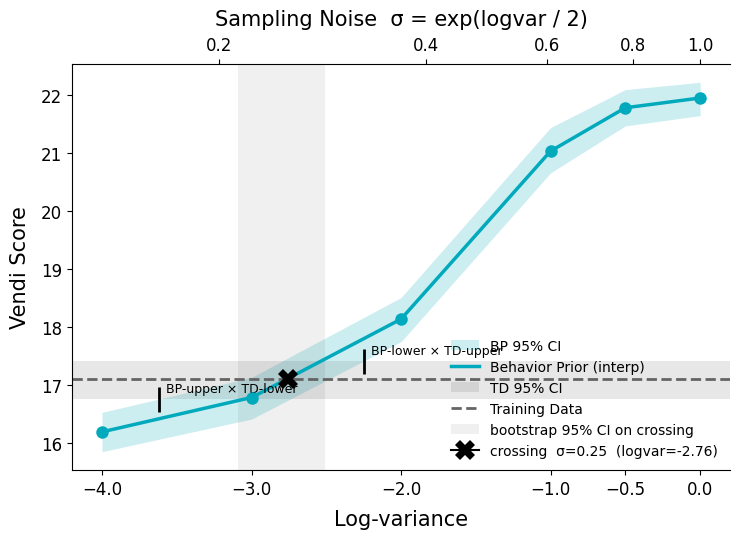

In [11]:
# Visualize the logvar-space linear interpolation used to locate the crossing.
fig, ax = plt.subplots(figsize=(7.5, 5.5))

# Fine grid in logvar for the piecewise-linear interpolation
lv_grid = np.linspace(stoch_logvars.min(), stoch_logvars.max(), 400)
bp_mean_interp = np.interp(lv_grid, stoch_logvars, bp_mean)
bp_lo_interp   = np.interp(lv_grid, stoch_logvars, bp_lo)
bp_hi_interp   = np.interp(lv_grid, stoch_logvars, bp_hi)

bp_color = (0 / 255, 170 / 255, 188 / 255)
td_color = (100 / 255, 100 / 255, 100 / 255)

# Behavior Prior: interpolated mean line + 95% CI band, plus the anchor points
ax.fill_between(lv_grid, bp_lo_interp, bp_hi_interp,
                color=bp_color, alpha=0.20, linewidth=0, label="BP 95% CI")
ax.plot(lv_grid, bp_mean_interp, "-", color=bp_color, lw=2.5,
        label="Behavior Prior (interp)")
ax.plot(stoch_logvars, bp_mean, "o", color=bp_color, ms=9, markeredgewidth=0,
        zorder=5)

# Training Data: horizontal line with its own 95% CI band
ax.axhspan(td_lo, td_hi, color=td_color, alpha=0.15, linewidth=0, label="TD 95% CI")
ax.axhline(td_mean, color=td_color, ls="--", lw=2, label="Training Data")

# Bootstrap CI on the crossing logvar (vertical band)
if n_v >= 2:
    ax.axvspan(lv_ci_lo, lv_ci_hi, color="black", alpha=0.06, linewidth=0,
               label="bootstrap 95% CI on crossing")

# Point-estimate crossing marker
if np.isfinite(lv_point):
    ax.plot(lv_point, td_mean, marker="X", color="black", ms=14, mew=0,
            zorder=6, label=f"crossing  σ={np.exp(lv_point/2):.2f}  (logvar={lv_point:.2f})")

# Band-overlap crossings (lower-BP vs upper-TD and upper-BP vs lower-TD)
for lv_mark, y_mark, tag in [
    (lv_confident_above, td_hi, "BP-lower × TD-upper"),
    (lv_last_below,      td_lo, "BP-upper × TD-lower"),
]:
    if np.isfinite(lv_mark):
        ax.plot(lv_mark, y_mark, marker="|", color="black", ms=18, mew=2, zorder=6)
        ax.annotate(tag, (lv_mark, y_mark), textcoords="offset points",
                    xytext=(5, 5), fontsize=9, color="black")

ax.set_xlabel("Log-variance", fontsize=15, labelpad=8)
ax.set_ylabel("Vendi Score", fontsize=15, labelpad=8)
ax.tick_params(labelsize=12)
ax.set_xticks(stoch_logvars)

# Secondary x-axis in sigma = exp(logvar / 2)
sec = ax.secondary_xaxis(
    "top",
    functions=(lambda lv: np.exp(lv / 2),
               lambda s: 2 * np.log(np.maximum(s, 1e-12))),
)
sec.set_xlabel("Sampling Noise  σ = exp(logvar / 2)", fontsize=15, labelpad=8)
sec.tick_params(labelsize=12)

for s in ["top", "right"]:
    ax.spines[s].set_visible(False)

ax.legend(fontsize=10, frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

## Paper figure: noise sweep with 95% bootstrap CIs

Two panels (Vendi, effective # clusters). For each panel: lines + shaded 95% CI bands for Behavior Prior and Motion Prior across all noise conditions, with horizontal dashed lines marking each model's deterministic encoder-decoder baseline.

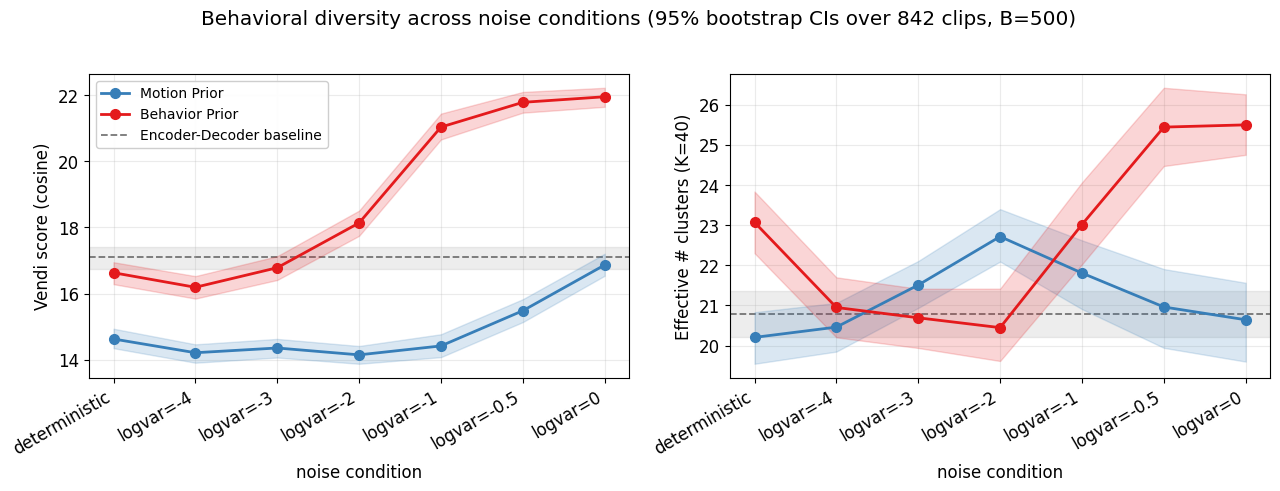

Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/behavioral_diversity/diversity_noise_sweep.png
Saved: /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/behavioral_diversity/diversity_noise_sweep.pdf


In [12]:
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 13,
    "axes.labelsize": 12,
    "legend.fontsize": 10,
})

COLORS = {"Motion Prior": "#377eb8", "Behavior Prior": "#e41a1c"}
BASELINE_COLOR = "#555555"
X = np.arange(len(CONDITION_ORDER))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for ax, key, ylabel in [
    (axes[0], "vendi", "Vendi score (cosine)"),
    (axes[1], "eff",   f"Effective # clusters (K={K})"),
]:
    boot_dict = boot_vendi if key == "vendi" else boot_eff

    # Random-rollout lines with CI bands
    for tag in FILES:
        means = np.array([np.mean(boot_dict[(tag, c)]) for c in CONDITION_ORDER])
        los = np.array([np.percentile(boot_dict[(tag, c)], 2.5) for c in CONDITION_ORDER])
        his = np.array([np.percentile(boot_dict[(tag, c)], 97.5) for c in CONDITION_ORDER])
        color = COLORS[tag]
        ax.plot(X, means, "o-", color=color, lw=2, ms=7, label=tag, zorder=3)
        ax.fill_between(X, los, his, color=color, alpha=0.18, zorder=2)

    # Single averaged encoder-decoder baseline with its own CI band
    ed_mean = np.mean(boot_dict[ENC_DEC_AVG])
    ed_lo = np.percentile(boot_dict[ENC_DEC_AVG], 2.5)
    ed_hi = np.percentile(boot_dict[ENC_DEC_AVG], 97.5)
    ax.axhline(ed_mean, color=BASELINE_COLOR, ls="--", lw=1.3, alpha=0.8,
               label="Encoder-Decoder baseline", zorder=1)
    ax.axhspan(ed_lo, ed_hi, color=BASELINE_COLOR, alpha=0.10, zorder=0)

    ax.set_xticks(X)
    ax.set_xticklabels(CONDITION_ORDER, rotation=30, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("noise condition")
    ax.grid(alpha=0.25)

axes[0].legend(loc="upper left", frameon=True, framealpha=0.95)
fig.suptitle(
    f"Behavioral diversity across noise conditions (95% bootstrap CIs over {n_clips} clips, B={BOOTSTRAP_B})",
    y=1.02,
)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "diversity_noise_sweep.png", dpi=200, bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "diversity_noise_sweep.pdf", bbox_inches="tight")
plt.show()
print(f"Saved: {OUTPUT_DIR / 'diversity_noise_sweep.png'}")
print(f"Saved: {OUTPUT_DIR / 'diversity_noise_sweep.pdf'}")


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/behavioral_diversity_vendi.[pdf|svg|png]


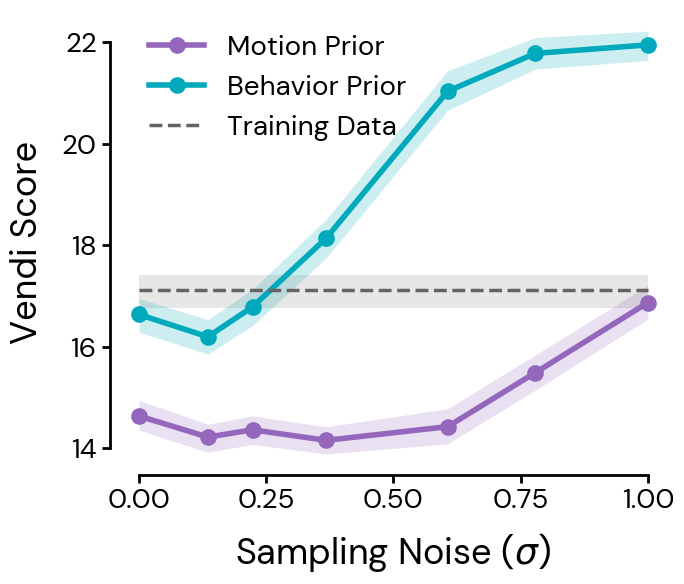

In [15]:
import matplotlib
import seaborn as sns
matplotlib.rcParams["font.family"] = "DM Sans"

PALETTE = {
    "Behavior Prior": tuple(c / 255 for c in (0, 170, 188)),
    "Motion Prior":             (148 / 255, 103 / 255, 189 / 255),
}
BASELINE_COLOR = tuple(c / 255 for c in (100, 100, 100))

# Sampling-noise sigma = exp(logvar/2). Data points sit at their true sigma on
# a continuous 0-1 axis; ticks are regular instead of at each data point.
SIGMA_BY_CONDITION = {
    "deterministic": 0.0,
    "logvar=-4":     float(np.exp(-4 / 2)),
    "logvar=-3":     float(np.exp(-3 / 2)),
    "logvar=-2":     float(np.exp(-2 / 2)),
    "logvar=-1":     float(np.exp(-1 / 2)),
    "logvar=-0.5":   float(np.exp(-0.5 / 2)),
    "logvar=0":      1.0,
}
X = np.array([SIGMA_BY_CONDITION[c] for c in CONDITION_ORDER])

fig, ax = plt.subplots(figsize=(7, 6))

for tag, display_name in [
    ("Motion Prior",   "Motion Prior"),
    ("Behavior Prior", "Behavior Prior"),
]:
    means = np.array([np.mean(boot_vendi[(tag, c)]) for c in CONDITION_ORDER])
    los   = np.array([np.percentile(boot_vendi[(tag, c)],  2.5) for c in CONDITION_ORDER])
    his   = np.array([np.percentile(boot_vendi[(tag, c)], 97.5) for c in CONDITION_ORDER])
    color = PALETTE[display_name]
    ax.plot(X, means, "o-", color=color, lw=4, ms=12, markeredgewidth=0, label=display_name)
    ax.fill_between(X, los, his, color=color, alpha=0.20, linewidth=0)

# Training Data (averaged encoder-decoder) baseline with 95% CI band
ed_mean = np.mean(boot_vendi[ENC_DEC_AVG])
ed_lo = np.percentile(boot_vendi[ENC_DEC_AVG], 2.5)
ed_hi = np.percentile(boot_vendi[ENC_DEC_AVG], 97.5)
ax.plot([X[0], X[-1]], [ed_mean, ed_mean],
        color=BASELINE_COLOR, ls="--", lw=2.5, label="Training Data")
ax.fill_between([X[0], X[-1]], [ed_lo, ed_lo], [ed_hi, ed_hi],
                color=BASELINE_COLOR, alpha=0.15, linewidth=0)

xticks = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
ax.set_xticks(xticks)
ax.set_xticklabels([f"{t:.2f}" for t in xticks])
ax.set_xlim(-0.03, 1.03)
ax.set_xlabel("Sampling Noise ($\\sigma$)", fontsize=26, labelpad=12)
ax.set_ylabel("Vendi Score", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)

sns.despine(ax=ax)

# Shift left spine outward, trim to tick range, trim bottom spine to tick range
ax.spines["left"].set_position(("outward", 10))
yticks = [t for t in ax.get_yticks() if ax.get_ylim()[0] <= t <= ax.get_ylim()[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])
ax.spines["bottom"].set_bounds(xticks[0], xticks[-1])
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.legend(fontsize=20, frameon=False, loc="upper left")

plt.tight_layout()

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "behavioral_diversity_vendi"
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/analysis/FinalNotebooks/Plots/behavioral_diversity_vendi_logvar.[pdf|svg|png]


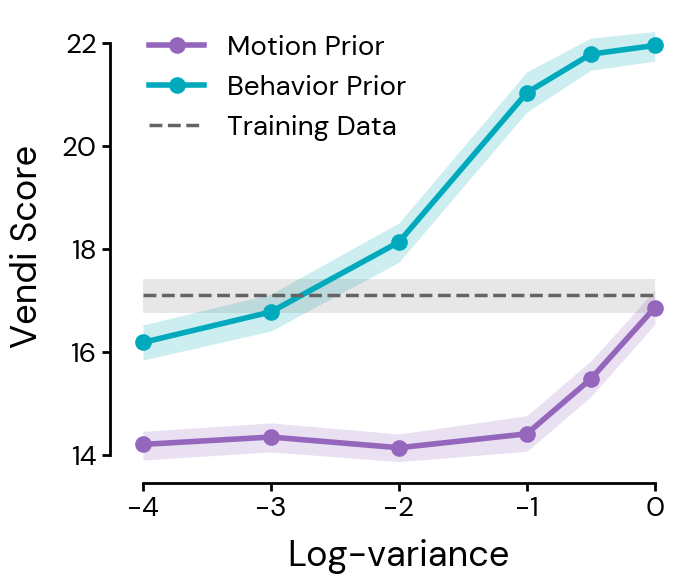

In [14]:
# Same bottom plot, but with log-variance on the x-axis and correct numerical
# spacing (deterministic has logvar=-inf, so it is excluded here).
matplotlib.rcParams["font.family"] = "DM Sans"

LOGVAR_CONDITIONS = [
    ("logvar=-4",   -4.0),
    ("logvar=-3",   -3.0),
    ("logvar=-2",   -2.0),
    ("logvar=-1",   -1.0),
    ("logvar=-0.5", -0.5),
    ("logvar=0",     0.0),
]
conds_lv  = [c for c, _ in LOGVAR_CONDITIONS]
logvars_x = np.array([lv for _, lv in LOGVAR_CONDITIONS])
tick_values = [lv for lv in logvars_x if lv != -0.5]

fig, ax = plt.subplots(figsize=(7, 6))

for tag, display_name in [
    ("Motion Prior",   "Motion Prior"),
    ("Behavior Prior", "Behavior Prior"),
]:
    means = np.array([np.mean(boot_vendi[(tag, c)]) for c in conds_lv])
    los   = np.array([np.percentile(boot_vendi[(tag, c)],  2.5) for c in conds_lv])
    his   = np.array([np.percentile(boot_vendi[(tag, c)], 97.5) for c in conds_lv])
    color = PALETTE[display_name]
    ax.plot(logvars_x, means, "o-", color=color, lw=4, ms=12,
            markeredgewidth=0, label=display_name)
    ax.fill_between(logvars_x, los, his, color=color, alpha=0.20, linewidth=0)

ed_mean = np.mean(boot_vendi[ENC_DEC_AVG])
ed_lo = np.percentile(boot_vendi[ENC_DEC_AVG], 2.5)
ed_hi = np.percentile(boot_vendi[ENC_DEC_AVG], 97.5)
ax.plot([logvars_x[0], logvars_x[-1]], [ed_mean, ed_mean],
        color=BASELINE_COLOR, ls="--", lw=2.5, label="Training Data")
ax.fill_between([logvars_x[0], logvars_x[-1]],
                [ed_lo, ed_lo], [ed_hi, ed_hi],
                color=BASELINE_COLOR, alpha=0.15, linewidth=0)

ax.set_xticks(tick_values)
ax.set_xticklabels([f"{lv:g}" for lv in tick_values])
pad = 0.15
ax.set_xlim(logvars_x[0] - pad, logvars_x[-1] + pad)
ax.set_xlabel("Log-variance", fontsize=26, labelpad=12)
ax.set_ylabel("Vendi Score", fontsize=26, labelpad=12)
ax.tick_params(labelsize=20, width=2, length=6)

sns.despine(ax=ax)
ax.spines["left"].set_position(("outward", 10))
yticks = [t for t in ax.get_yticks() if ax.get_ylim()[0] <= t <= ax.get_ylim()[1]]
ax.spines["left"].set_bounds(yticks[0], yticks[-1])
ax.spines["bottom"].set_bounds(logvars_x[0], logvars_x[-1])
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.legend(fontsize=20, frameon=False, loc="upper left")

plt.tight_layout()

save_name = "behavioral_diversity_vendi_logvar"
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()
